In [7]:
import akshare as ak
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]   # 中文不乱码
plt.rcParams["axes.unicode_minus"] = False      # 负号不乱码


In [8]:
# 候选接口一：中债国债/国开收益率曲线
df = ak.bond_china_yield(start_date="20260101", end_date="20261101")
df.head()      # 前五行：先看长什么样
df.info()      # 数据体检：多少行、哪些列、有没有缺失

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   曲线名称    612 non-null    str    
 1   日期      612 non-null    object 
 2   3月      612 non-null    float64
 3   6月      612 non-null    float64
 4   1年      612 non-null    float64
 5   3年      612 non-null    float64
 6   5年      612 non-null    float64
 7   7年      612 non-null    float64
 8   10年     612 non-null    float64
 9   30年     408 non-null    float64
dtypes: float64(8), object(1), str(1)
memory usage: 47.9+ KB


DatetimeIndex(['2026-01-04', '2026-01-05', '2026-01-06'], dtype='datetime64[s]',
              name='日期', freq=None)


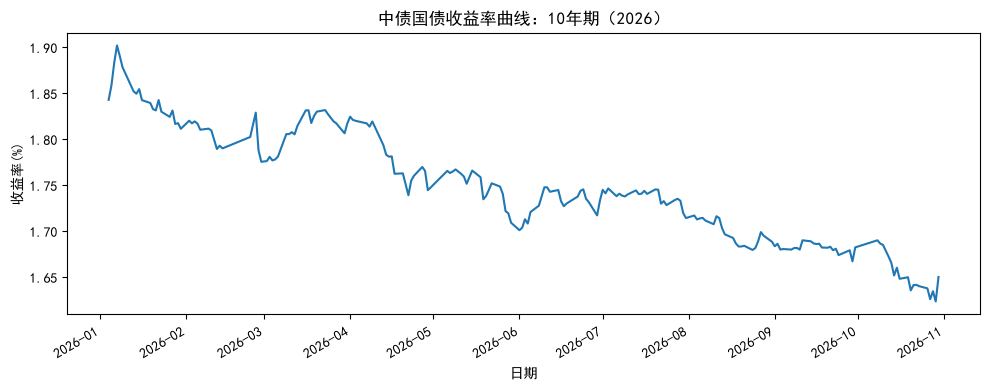

In [11]:
# ① 筛国债曲线
gov = df[df["曲线名称"] == "中债国债收益率曲线"].copy()

# ② 文字日期 → 真正的时间类型（必须在做索引之前转）
gov["日期"] = pd.to_datetime(gov["日期"])

# ③ 把日期列立为索引并排序
gov = gov.set_index("日期").sort_index()

# ④ 先验证索引，再画图
print(gov.index[:3])          # 应看到 DatetimeIndex 和真实日期

gov["10年"].plot(figsize=(10, 4), title="中债国债收益率曲线：10年期（2026）")
plt.ylabel("收益率(%)")
plt.tight_layout()
plt.savefig("../reports/gov_10y_2026.png", dpi=150)

In [10]:
df.to_csv("../data/cn_gov_curve_raw.csv", encoding="utf-8-sig")
print("已保存", df.shape)


已保存 (612, 10)
